# BiLSTM + GloVe Sentiment Analysis — Amazon Reviews

Analiza sentymentu za pomocą dwukierunkowej sieci LSTM (BiLSTM) w PyTorch z lokalnymi embeddingami GloVe.

**Konfiguracja:**
- Framework: PyTorch
- Embeddingi: GloVe 6B 100d z pliku `data/glove.6B.100d.txt` (zamrożone)
- Klasyfikator: BiLSTM + warstwa liniowa
- 3 klasy: 0 = Negative, 1 = Neutral, 2 = Positive
- Metryka główna: `F1-macro`, tak jak w eksperymencie SVM

**Podział danych:**
```
Cały dataset
│
├── Train      (70%)  ← trening sieci
├── Validation (10%)  ← early stopping, wybór najlepszej epoki
└── Test       (20%)  ← finalna ewaluacja, dotykamy tylko raz
```

**Dlaczego validation jest konieczny przy BiLSTM:**
Sieć neuronowa trenuje się przez wiele epok — bez monitorowania na niezależnym zbiorze
nie wiadomo kiedy zatrzymać trening. Early stopping śledzi validation loss i zatrzymuje
trening gdy przestaje spadać, a wagi z najlepszej epoki są zapisywane i używane finalnie.

**Uwaga o porównaniu z SVM:**
SVM używał podziału Train/Test 80/20 oraz walidacji krzyżowej na zbiorze treningowym. BiLSTM potrzebuje dodatkowego zbioru walidacyjnego do early stopping, dlatego dzielimy dane na Train/Validation/Test 70/10/20. Test nadal stanowi te same 20% danych, odłożone przed uczeniem.

## 1. Importy

In [1]:
import pandas as pd
import numpy as np
import time
import os
import copy
import re

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import seaborn as sns
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

print(f"Urzadzenie: {DEVICE}")
print(f"PyTorch: {torch.__version__}")

Urzadzenie: mps
PyTorch: 2.11.0


## 2. Wczytanie danych

In [2]:
df = pd.read_csv('data/processed_reviews.csv')

print(f"Liczba probek: {len(df)}")
print(f"Kolumny: {df.columns.tolist()}")
print("\nRozklad klas (label):")
print(df['label'].value_counts().sort_index())

df.head(3)

Liczba probek: 89511
Kolumny: ['id', 'full_text', 'score', 'sentiment', 'label']

Rozklad klas (label):
label
0    29837
1    29837
2    29837
Name: count, dtype: int64


,id,full_text,score,sentiment,label
0,497575,It's not equal amounts of each flavor... Just ...,3,0,1
1,333710,Not A Gingerbread Man These do taste very good...,4,1,2
2,275773,"great taste great taste, good price... Always ...",5,1,2


## 3. Podział danych: Train / Validation / Test

Stratyfikacja zapewnia taki sam rozkład klas we wszystkich trzech zbiorach.

In [3]:
def clean_text(text):
    text = str(text)
    text = re.sub(r'<[^>]+>', ' ', text)       # usuwa tagi HTML, np. <br />
    text = re.sub(r'http\S+|www\S+', ' ', text)  # usuwa adresy URL
    text = re.sub(r'\s+', ' ', text).strip()   # normalizuje biale znaki
    return text

X = df['full_text'].map(clean_text)
y = df['label'].astype(int)

print("Przyklad po lekkim czyszczeniu HTML/URL:")
display(X.head(3))


# Krok 1: Odłóż test (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

# Krok 2: Z pozostałych 80% wydziel validation (0.125 * 0.80 = 0.10 całości)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=SEED, stratify=y_temp
)

print(f"Train:      {len(X_train):>6} probek ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation: {len(X_val):>6} probek ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test:       {len(X_test):>6} probek ({len(X_test)/len(X)*100:.1f}%)")
print("\nRozklad klas w Train:")
print(y_train.value_counts().sort_index())
print("\nRozklad klas w Validation:")
print(y_val.value_counts().sort_index())
print("\nRozklad klas w Test:")
print(y_test.value_counts().sort_index())

Przyklad po lekkim czyszczeniu HTML/URL:


0    It's not equal amounts of each flavor... Just ...
1    Not A Gingerbread Man These do taste very good...
2    great taste great taste, good price... Always ...
Name: full_text, dtype: object

Train:       62657 probek (70.0%)
Validation:   8951 probek (10.0%)
Test:        17903 probek (20.0%)

Rozklad klas w Train:
label
0    20886
1    20885
2    20886
Name: count, dtype: int64

Rozklad klas w Validation:
label
0    2984
1    2984
2    2983
Name: count, dtype: int64

Rozklad klas w Test:
label
0    5967
1    5968
2    5968
Name: count, dtype: int64


## 4. Tokenizacja i budowa słownika

Słownik budujemy **tylko na `X_train`** — żeby uniknąć data leakage.
Słowa z validation i test które nie są w słowniku dostaną token `<UNK>`.

Przed tokenizacją usuwamy tagi HTML (np. `<br />`), adresy URL i nadmiarowe białe znaki. Tokenizer jest prosty, ale usuwa podstawową interpunkcję i zostawia apostrofy wewnątrz słów, dzięki czemu lepiej pasuje do formatu GloVe niż zwykłe `split()`.

In [4]:
from collections import Counter

MAX_VOCAB = 30000  # maksymalna liczba slow w slowniku
MAX_LEN   = 200    # maksymalna długość sekwencji w tokenach
MIN_FREQ  = 3      # minimalna częstość słowa (analogicznie do min_df w TF-IDF)

PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'

TOKEN_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")

def simple_tokenize(text):
    return TOKEN_PATTERN.findall(clean_text(text).lower())

# Budujemy słownik tylko na train
counter = Counter()
for text in X_train:
    counter.update(simple_tokenize(text))

vocab_words = [w for w, c in counter.most_common(MAX_VOCAB) if c >= MIN_FREQ]
vocab = [PAD_TOKEN, UNK_TOKEN] + vocab_words
word2idx = {w: i for i, w in enumerate(vocab)}

PAD_IDX = word2idx[PAD_TOKEN]
UNK_IDX = word2idx[UNK_TOKEN]

print(f"Rozmiar slownika: {len(vocab)} slow")
print(f"PAD_IDX={PAD_IDX}, UNK_IDX={UNK_IDX}")

def encode(text, max_len=MAX_LEN):
    """Zamienia tekst na liste indeksow, przycina lub padduje do max_len."""
    tokens = simple_tokenize(text)[:max_len]
    ids = [word2idx.get(t, UNK_IDX) for t in tokens]
    ids += [PAD_IDX] * (max_len - len(ids))
    return ids

Rozmiar slownika: 22665 slow
PAD_IDX=0, UNK_IDX=1


## 5. Wczytanie embeddingów GloVe

Używamy lokalnego pliku `data/glove.6B.100d.txt` (GloVe 6B 100d) — to rozsądny kompromis między jakością reprezentacji i kosztem treningu na CPU.

Embeddingi są **zamrożone** (`requires_grad=False`) — nie trenujemy ich od nowa.
Dzięki temu trening na CPU jest znacznie szybszy, a GloVe już zawiera
bogatą wiedzę o semantyce słów.

In [5]:
GLOVE_PATH  = 'data/glove.6B.100d.txt'
EMBED_DIM   = 100

def load_glove(glove_path, word2idx, embed_dim):
    """Wczytuje GloVe i buduje macierz embeddingów dopasowaną do słownika."""
    vocab_size = len(word2idx)
    # Inicjalizujemy losowo — słowa bez GloVe dostaną losowy wektor
    embedding_matrix = np.random.uniform(-0.1, 0.1, (vocab_size, embed_dim))
    # PAD zawsze zerowy
    embedding_matrix[PAD_IDX] = np.zeros(embed_dim)

    found = 0
    if not os.path.exists(glove_path):
        raise FileNotFoundError(f"Brak pliku GloVe: {glove_path}")

    with open(glove_path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            word = parts[0]
            if word in word2idx:
                embedding_matrix[word2idx[word]] = np.array(parts[1:], dtype=np.float32)
                found += 1

    print(f"Znaleziono wektory GloVe dla {found}/{vocab_size} slow "
          f"({found/vocab_size*100:.1f}%)")
    return torch.FloatTensor(embedding_matrix)

embedding_matrix = load_glove(GLOVE_PATH, word2idx, EMBED_DIM)
print(f"Ksztalt macierzy embeddingow: {embedding_matrix.shape}")

Znaleziono wektory GloVe dla 19886/22665 slow (87.7%)
Ksztalt macierzy embeddingow: torch.Size([22665, 100])


## 6. Dataset i DataLoader

In [6]:
class SentimentDataset(Dataset):
    def __init__(self, texts, labels):
        self.X = [torch.tensor(encode(t), dtype=torch.long) for t in texts]
        self.y = torch.tensor(labels.values, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Batch size dobrany tak, zeby trening byl stabilny i nadal wykonalny na CPU.
BATCH_SIZE = 64

train_dataset = SentimentDataset(X_train, y_train)
val_dataset   = SentimentDataset(X_val,   y_val)
test_dataset  = SentimentDataset(X_test,  y_test)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batche:      {len(train_loader)}")
print(f"Validation batche: {len(val_loader)}")
print(f"Test batche:       {len(test_loader)}")

Train batche:      980
Validation batche: 140
Test batche:       280


## 7. Architektura BiLSTM

```
Input (batch, MAX_LEN)
    ↓
Embedding (frozen GloVe)  →  (batch, MAX_LEN, 100)
    ↓
BiLSTM (hidden=128, layers=2)  →  (batch, MAX_LEN, 256)  [128 forward + 128 backward]
    ↓
Mean pooling po sekwencji  →  (batch, 256)
    ↓
Dropout (0.4)
    ↓
Linear (256 → 3)
    ↓
Output: logits dla 3 klas
```

Mean pooling zamiast ostatniego hidden state — lepiej agreguje informację
z całej sekwencji, szczególnie przy długich recenzjach.

In [7]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, num_layers, num_classes, dropout):
        super().__init__()

        vocab_size, embed_dim = embedding_matrix.shape

        # Warstwa embeddingów — zamrożona (nie uczy się podczas treningu)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.embedding.weight = nn.Parameter(embedding_matrix, requires_grad=False)

        # BiLSTM — bidirectional=True podwaja wymiar wyjściowy
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.dropout = nn.Dropout(dropout)

        # hidden_dim * 2 bo BiLSTM (forward + backward)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        # x: (batch, seq_len)
        embedded = self.dropout(self.embedding(x))   # (batch, seq_len, embed_dim)
        output, _ = self.lstm(embedded)              # (batch, seq_len, hidden*2)

        # Mean pooling — uśredniamy po całej sekwencji
        # Ignorujemy pozycje paddingu przy liczeniu średniej
        mask = (x != PAD_IDX).unsqueeze(-1).float()  # (batch, seq_len, 1)
        pooled = (output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)

        out = self.dropout(pooled)                   # (batch, hidden*2)
        logits = self.fc(out)                        # (batch, num_classes)
        return logits


# Hiperparametry modelu
HIDDEN_DIM  = 128
NUM_LAYERS  = 2
DROPOUT     = 0.4
NUM_CLASSES = 3

model = BiLSTMClassifier(
    embedding_matrix=embedding_matrix,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nLaczna liczba parametrow:     {total_params:,}")
print(f"Trenowalne parametry:          {trainable_params:,}")
print(f"Zamrozone (embeddingi GloVe):  {total_params - trainable_params:,}")

BiLSTMClassifier(
  (embedding): Embedding(22665, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)

Laczna liczba parametrow:     2,898,055
Trenowalne parametry:          631,555
Zamrozone (embeddingi GloVe):  2,266,500


## 8. Funkcje treningowe

In [8]:
def train_epoch(model, loader, optimizer, criterion):
    """Jedna epoka treningu — zwraca średni loss i F1-macro."""
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()

        # Gradient clipping — zapobiega eksplodującym gradientom w LSTM
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_loss += loss.item()
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_batch.cpu().numpy())

    avg_loss = total_loss / len(loader)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, f1


def evaluate(model, loader, criterion):
    """Ewaluacja na dowolnym zbiorze — zwraca loss, F1 i predykcje."""
    model.eval()
    total_loss = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            total_loss += loss.item()
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(y_batch.cpu().numpy())

    avg_loss = total_loss / len(loader)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, f1, all_preds, all_labels


print("Funkcje treningowe zdefiniowane.")

Funkcje treningowe zdefiniowane.


## 9. Trening z Early Stopping

Early stopping śledzi `validation loss` — gdy nie poprawia się przez `patience` epok,
trening zostaje zatrzymany. Wagi z **najlepszej epoki** są zapisywane i używane finalnie.

`ReduceLROnPlateau` zmniejsza learning rate gdy validation loss staje w miejscu —
pomaga modelowi wyjść z lokalnego minimum bez ręcznego dostrajania LR.

In [9]:
# Hiperparametry treningu
LEARNING_RATE = 1e-3
MAX_EPOCHS    = 20
PATIENCE      = 3     # ile epok bez poprawy zanim zatrzymamy trening
WEIGHT_DECAY  = 1e-5  # L2 regularization

criterion = nn.CrossEntropyLoss()
optimizer = Adam(filter(lambda p: p.requires_grad, model.parameters()),
                 lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)

# Historia metryk do wykresów
history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}

best_val_loss   = float('inf')
best_model_wts  = copy.deepcopy(model.state_dict())
epochs_no_improve = 0
best_epoch      = 0

print(f"Trening BiLSTM — max {MAX_EPOCHS} epok, patience={PATIENCE}")
print("=" * 65)

start = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    t0 = time.time()

    train_loss, train_f1 = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_f1, _, _ = evaluate(model, val_loader, criterion)

    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_f1'].append(train_f1)
    history['val_f1'].append(val_f1)

    epoch_time = time.time() - t0
    print(f"Epoka {epoch:>2}/{MAX_EPOCHS} | "
          f"Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | "
          f"Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f} | "
          f"{epoch_time:.0f}s")

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss  = val_loss
        best_model_wts = copy.deepcopy(model.state_dict())
        best_epoch     = epoch
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping po epoce {epoch} "
                  f"(brak poprawy przez {PATIENCE} epoki)")
            break

# Wczytujemy wagi z najlepszej epoki
model.load_state_dict(best_model_wts)
print(f"\nCalkowity czas treningu: {time.time() - start:.0f}s")
print(f"Najlepsza epoka: {best_epoch} (val loss: {best_val_loss:.4f})")

Trening BiLSTM — max 20 epok, patience=3
Epoka  1/20 | Train loss: 0.8535 | Val loss: 0.6807 | Train F1: 0.5926 | Val F1: 0.6983 | 103s
Epoka  2/20 | Train loss: 0.7124 | Val loss: 0.6374 | Train F1: 0.6810 | Val F1: 0.7157 | 104s
Epoka  3/20 | Train loss: 0.6587 | Val loss: 0.5806 | Train F1: 0.7111 | Val F1: 0.7497 | 98s
Epoka  4/20 | Train loss: 0.6297 | Val loss: 0.5575 | Train F1: 0.7277 | Val F1: 0.7570 | 98s
Epoka  5/20 | Train loss: 0.6061 | Val loss: 0.5565 | Train F1: 0.7375 | Val F1: 0.7590 | 98s
Epoka  6/20 | Train loss: 0.5895 | Val loss: 0.5387 | Train F1: 0.7468 | Val F1: 0.7683 | 101s
Epoka  7/20 | Train loss: 0.5755 | Val loss: 0.5319 | Train F1: 0.7534 | Val F1: 0.7663 | 103s
Epoka  8/20 | Train loss: 0.5626 | Val loss: 0.5245 | Train F1: 0.7615 | Val F1: 0.7683 | 97s
Epoka  9/20 | Train loss: 0.5539 | Val loss: 0.5168 | Train F1: 0.7658 | Val F1: 0.7747 | 97s
Epoka 10/20 | Train loss: 0.5432 | Val loss: 0.5115 | Train F1: 0.7694 | Val F1: 0.7784 | 100s
Epoka 11/20 | 

## 10. Krzywe uczenia

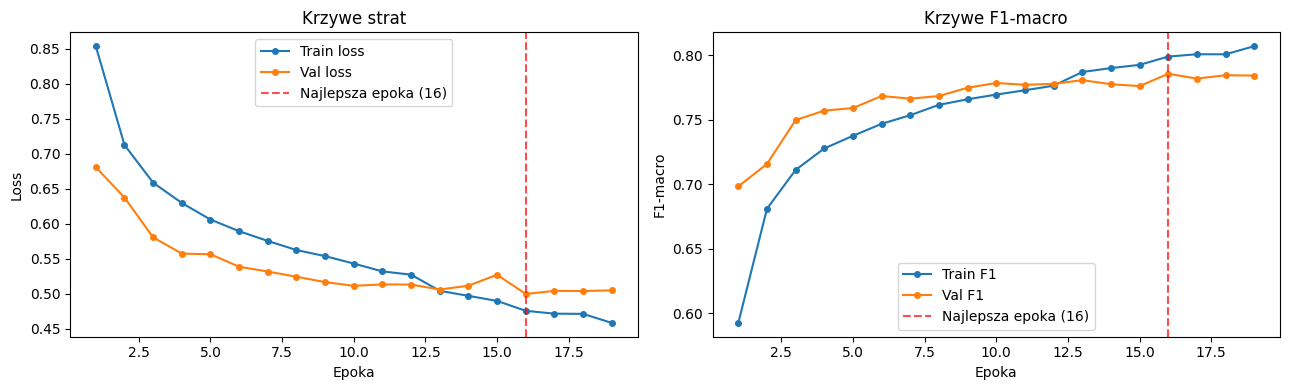

Gap train-val F1 w najlepszej epoce: +0.0133 <-- ok


In [10]:
epochs_ran = len(history['train_loss'])
ep = range(1, epochs_ran + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

# Loss
ax1.plot(ep, history['train_loss'], label='Train loss', marker='o', markersize=4)
ax1.plot(ep, history['val_loss'],   label='Val loss',   marker='o', markersize=4)
ax1.axvline(best_epoch, color='red', linestyle='--', alpha=0.7,
            label=f'Najlepsza epoka ({best_epoch})')
ax1.set_xlabel('Epoka')
ax1.set_ylabel('Loss')
ax1.set_title('Krzywe strat')
ax1.legend()

# F1
ax2.plot(ep, history['train_f1'], label='Train F1', marker='o', markersize=4)
ax2.plot(ep, history['val_f1'],   label='Val F1',   marker='o', markersize=4)
ax2.axvline(best_epoch, color='red', linestyle='--', alpha=0.7,
            label=f'Najlepsza epoka ({best_epoch})')
ax2.set_xlabel('Epoka')
ax2.set_ylabel('F1-macro')
ax2.set_title('Krzywe F1-macro')
ax2.legend()

plt.tight_layout()
plt.show()

# Sygnał overfittingu — jeśli train F1 >> val F1, model się przeuczył
gap = history['train_f1'][best_epoch-1] - history['val_f1'][best_epoch-1]
print(f"Gap train-val F1 w najlepszej epoce: {gap:+.4f}",
      "<-- ok" if gap < 0.05 else "<-- uwaga, mozliwe przeuczenie")

## 11. Ewaluacja na zbiorze walidacyjnym

WYNIKI NA ZBIORZE WALIDACYJNYM
F1-macro (validation): 0.7856

              precision    recall  f1-score   support

Negative (0)       0.79      0.76      0.78      2984
 Neutral (1)       0.69      0.72      0.70      2984
Positive (2)       0.87      0.88      0.88      2983

    accuracy                           0.79      8951
   macro avg       0.79      0.79      0.79      8951
weighted avg       0.79      0.79      0.79      8951



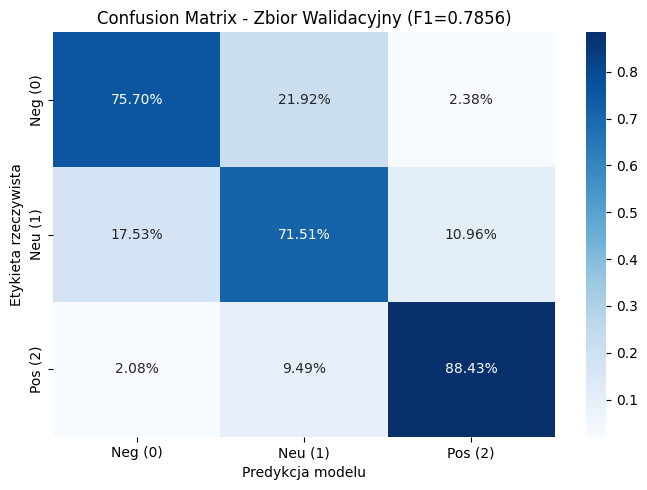

In [11]:
_, val_f1_final, val_preds, val_labels = evaluate(model, val_loader, criterion)

print("=" * 55)
print("WYNIKI NA ZBIORZE WALIDACYJNYM")
print("=" * 55)
print(f"F1-macro (validation): {val_f1_final:.4f}")
print()
print(classification_report(
    val_labels, val_preds,
    target_names=['Negative (0)', 'Neutral (1)', 'Positive (2)']
))

cm_val = confusion_matrix(val_labels, val_preds)
cm_val_pct = cm_val.astype(float) / cm_val.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_val_pct, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Neg (0)', 'Neu (1)', 'Pos (2)'],
            yticklabels=['Neg (0)', 'Neu (1)', 'Pos (2)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix - Zbior Walidacyjny (F1={val_f1_final:.4f})')
plt.tight_layout()
plt.show()

## 12. Finalna ewaluacja na zbiorze testowym

> **Uwaga**: Ta sekcja uruchamiana jest tylko raz, po zakończeniu wszystkich eksperymentów.
> Wyniki testowe nie mogą wpływać na żadne dalsze decyzje modelarskie.

FINALNE WYNIKI NA ZBIORZE TESTOWYM
Val F1-macro  (najlepsza epoka): 0.7856
Test F1-macro (FINALNA):         0.7841

              precision    recall  f1-score   support

Negative (0)       0.80      0.75      0.78      5967
 Neutral (1)       0.69      0.72      0.71      5968
Positive (2)       0.87      0.87      0.87      5968

    accuracy                           0.78     17903
   macro avg       0.79      0.78      0.78     17903
weighted avg       0.79      0.78      0.78     17903



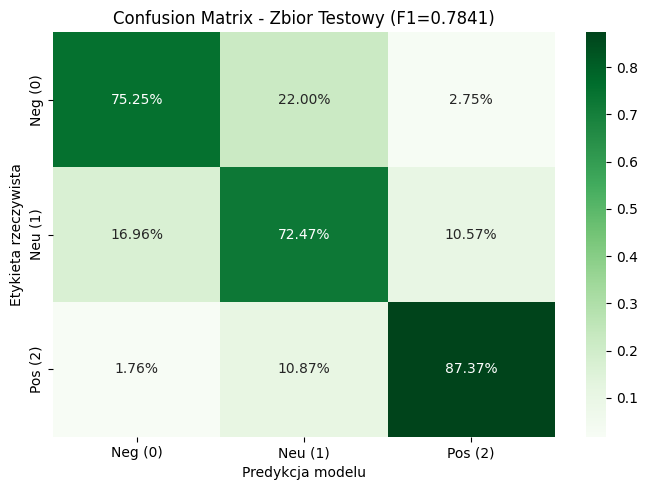

In [12]:
_, test_f1, test_preds, test_labels = evaluate(model, test_loader, criterion)

print("=" * 55)
print("FINALNE WYNIKI NA ZBIORZE TESTOWYM")
print("=" * 55)
print(f"Val F1-macro  (najlepsza epoka): {val_f1_final:.4f}")
print(f"Test F1-macro (FINALNA):         {test_f1:.4f}")
print()
print(classification_report(
    test_labels, test_preds,
    target_names=['Negative (0)', 'Neutral (1)', 'Positive (2)']
))

cm_test = confusion_matrix(test_labels, test_preds)
cm_test_pct = cm_test.astype(float) / cm_test.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_test_pct, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=['Neg (0)', 'Neu (1)', 'Pos (2)'],
            yticklabels=['Neg (0)', 'Neu (1)', 'Pos (2)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix - Zbior Testowy (F1={test_f1:.4f})')
plt.tight_layout()
plt.show()

## 13. Podsumowanie

In [13]:
print("=" * 55)
print("PODSUMOWANIE EKSPERYMENTU")
print("=" * 55)
print(f"\nArchitektura:")
print(f"  BiLSTM hidden dim:  {HIDDEN_DIM} (x2 = {HIDDEN_DIM*2} bidirectional)")
print(f"  Liczba warstw LSTM: {NUM_LAYERS}")
print(f"  Dropout:            {DROPOUT}")
print(f"  Embeddingi:         GloVe 6B 100d (zamrozone)")
print(f"  Max dlugosc seq.:   {MAX_LEN} tokenow")
print(f"\nPodzial danych:")
print(f"  Train:      {len(X_train):>6} probek (70%)")
print(f"  Validation: {len(X_val):>6} probek (10%)")
print(f"  Test:       {len(X_test):>6} probek (20%)")
print(f"\nTrening:")
print(f"  Najlepsza epoka:       {best_epoch}/{epochs_ran}")
print(f"  Best val loss:         {best_val_loss:.4f}")
print(f"\nWyniki:")
print(f"  Val F1-macro:          {val_f1_final:.4f}")
print(f"  Test F1-macro (FINAL): {test_f1:.4f}")

PODSUMOWANIE EKSPERYMENTU

Architektura:
  BiLSTM hidden dim:  128 (x2 = 256 bidirectional)
  Liczba warstw LSTM: 2
  Dropout:            0.4
  Embeddingi:         GloVe 6B 100d (zamrozone)
  Max dlugosc seq.:   200 tokenow

Podzial danych:
  Train:       62657 probek (70%)
  Validation:   8951 probek (10%)
  Test:        17903 probek (20%)

Trening:
  Najlepsza epoka:       16/19
  Best val loss:         0.4998

Wyniki:
  Val F1-macro:          0.7856
  Test F1-macro (FINAL): 0.7841


## 14. Porównanie z modelem SVM

Poniżej zestawiamy finalny wynik BiLSTM z wynikiem `svm_sentiment_final.ipynb`. Warto pamiętać, że BiLSTM używa osobnego zbioru walidacyjnego do early stopping, ale finalny test nadal pozostaje odłożonym zbiorem 20% danych.

,model,test_f1_macro,delta_vs_svm
0,SVM + TF-IDF,0.776100,0.000000
1,BiLSTM + GloVe,0.784127,0.008027


/var/folders/4p/1fp7f9tn50qd5dg43z45lvz00000gn/T/ipykernel_71116/1852749177.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='model', y='test_f1_macro', palette=['steelblue', 'seagreen'])


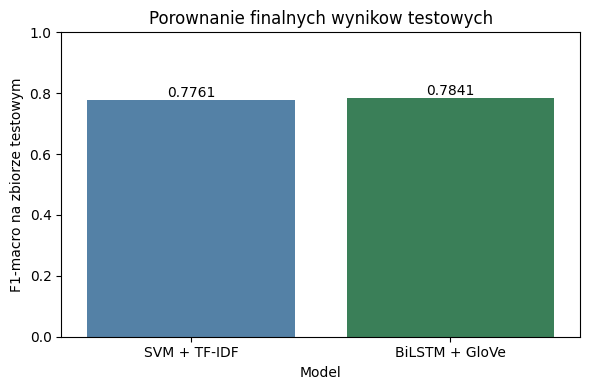

Roznica BiLSTM - SVM: +0.0080 F1-macro


In [14]:
svm_test_f1 = 0.7761  # wynik z notebooka svm_sentiment_final.ipynb

comparison_df = pd.DataFrame({
    'model': ['SVM + TF-IDF', 'BiLSTM + GloVe'],
    'test_f1_macro': [svm_test_f1, test_f1]
})
comparison_df['delta_vs_svm'] = comparison_df['test_f1_macro'] - svm_test_f1

display(comparison_df)

plt.figure(figsize=(6, 4))
sns.barplot(data=comparison_df, x='model', y='test_f1_macro', palette=['steelblue', 'seagreen'])
plt.ylim(0, 1)
plt.ylabel('F1-macro na zbiorze testowym')
plt.xlabel('Model')
plt.title('Porownanie finalnych wynikow testowych')
for i, score in enumerate(comparison_df['test_f1_macro']):
    plt.text(i, score + 0.01, f'{score:.4f}', ha='center')
plt.tight_layout()
plt.show()

delta = test_f1 - svm_test_f1
print(f"Roznica BiLSTM - SVM: {delta:+.4f} F1-macro")

> **Uwaga:** wartość `svm_test_f1 = 0.7761` pochodzi z wcześniejszej wersji notebooka SVM, w której tekst był dodatkowo czyszczony z tagów HTML i adresów URL. Finalny wynik z `svm_sentiment_final.ipynb` to **0.7768**; różnica (0.0007) nie wpływa na wnioski.

## 15. Analiza błędów

In [15]:
results_df = pd.DataFrame({
    'text':      X_test.values,
    'actual':    test_labels,
    'predicted': test_preds
})

errors = results_df[results_df['actual'] != results_df['predicted']]
print(f"Blednych predykcji: {len(errors)} / {len(results_df)} "
      f"({len(errors)/len(results_df)*100:.1f}%)")

# Skrajne pomyłki: Negatyw (0) → Pozytyw (2)
extreme = errors[(errors['actual'] == 0) & (errors['predicted'] == 2)]
print(f"\nSkrajne pomylki (Negatyw -> Pozytyw): {len(extreme)}")

for _, row in extreme.head(5).iterrows():
    print(f"\n[actual={row['actual']} | pred={row['predicted']}]")
    print(f"  {str(row['text'])[:250]}...")

Blednych predykcji: 3874 / 17903 (21.6%)

Skrajne pomylki (Negatyw -> Pozytyw): 164

[actual=0 | pred=2]
  frenchs horseradish mustard first of all I like Frenchs regular and deli mustards but when it comes to horseradish mustard they really havent got a clue there horseradish mustard sucks its not hot at all you cannot tast the horseradish at all in fact...

[actual=0 | pred=2]
  $26.00 for a $7.00 worth of product??????????????????? the miracle whip is $3.50 each in the store.are these people insane!! plus almost $10 to ship...yes, these people are insane. oh well it was worth a laugh just to see the price...

[actual=0 | pred=2]
  Great product....don't order on amazon The chocolate is just as delicious as could be expected. The wrap is easy to remove and re wrap again. The kisses in the inside come in a nice bag, keeping them safe inside. The box it comes in is sturdy enough....

[actual=0 | pred=2]
  Careful! Read the back of can....... I did agree with these two reviews. Excellen